# Business Understanding & Metodologi: Sistem Peringatan Kebisingan Cerdas (Smart Noise Alert System)
**Studi Kasus:** Laboratorium Teknik Informatika, Universitas Trunojoyo Madura (UTM)  
**Mata Kuliah:** Penambangan Sains Data  

---

## 1. Latar Belakang & Permasalahan (Background & Problem Statement)
Laboratorium di lingkungan Departemen Teknik Informatika Universitas Trunojoyo Madura (UTM) merupakan fasilitas utama yang digunakan untuk kegiatan praktikum, penelitian mahasiswa, asistensi, dan pengerjaan proyek akhir. Kondisi lingkungan laboratorium yang kondusif dan tenang sangat dibutuhkan agar konsentrasi praktikan maupun peneliti tetap terjaga.

Namun, seiring tingginya mobilitas mahasiswa di dalam laboratorium, sering terjadi peningkatan kebisingan akibat diskusi kelompok atau obrolan serentak yang melampaui batas wajar. Pengawasan secara manual oleh asisten laboratorium sering kali tidak efektif karena asisten harus fokus membimbing praktikan. Selain itu, alat pendeteksi kebisingan konvensional yang hanya mengandalkan ambang batas desibel (dB) sering mengalami kesalahan deteksi (*false alarm*) akibat suara sesaat seperti kursi bergeser, benda jatuh, atau dengung konstan dari mesin AC dan kipas PC server laboratorium.

---

## 2. Tujuan Bisnis (Business Objectives)
Membangun **Sistem Peringatan Kebisingan Cerdas (Smart Noise Alert System)** di Laboratorium Teknik Informatika UTM yang mampu:
1. **Mendeteksi Keramaian Secara Akurat:** Membedakan secara cerdas antara kondisi ruangan yang benar-benar "Berisik/Ramai" (banyak percakapan manusia secara bersamaan) dengan kondisi "Tidak Berisik/Tenang" (suasana hening, suara ketikan keyboard/klik mouse wajar, atau dengung konstan mesin AC/komputer).
2. **Otomatisasi Peringatan (Alarm Trigger):** Mengaktifkan pemicu (*trigger*) berupa alarm peringatan suara otomatis, lampu indikator peringatan, atau notifikasi ke meja asisten ketika terdeteksi kondisi berisik yang berkelanjutan.
3. **Efisiensi Pengawasan Laboratorium:** Membantu kepala laboratorium dan asisten laboratorium dalam menjaga ketertiban ruangan secara objektif tanpa harus menegur secara manual terus-menerus.

---

## 3. Tujuan Penambangan Data (Data Mining Goals)
Menerjemahkan kebutuhan operasional laboratorium ke dalam tahapan teknis *Machine Learning*:
* **Formulasi Masalah:** Klasifikasi Biner (*Binary Classification*) terhadap data sinyal audio menjadi dua kelas target, yaitu Kelas `1` (**Berisik**) dan Kelas `0` (**Tidak Berisik**).
* **Ekstraksi & Agregasi Fitur Akustik (`librosa`):** Mengubah sinyal audio *time-series* berdurasi 5–10 detik menjadi vektor fitur statis (nilai rata-rata/*mean* dan simpangan baku/*standard deviation*) yang mencakup:
  * **RMS (Root Mean Square):** Mengukur tingkat energi atau kenyaringan suara ($2\text{ fitur}$).
  * **Spectral Centroid:** Mengukur pusat distribusi frekuensi untuk membedakan karakter suara vokal manusia dengan dengung frekuensi rendah mesin AC ($2\text{ fitur}$).
  * **Zero Crossing Rate (ZCR):** Mengukur tingkat fluktuasi sinyal ($2\text{ fitur}$).
  * **13 Koefisien MFCC (Mel-Frequency Cepstral Coefficients):** Menangkap karakteristik *timbre* atau warna suara percakapan manusia ($26\text{ fitur}$).
* **Pemodelan & Interpretabilitas:** Melatih algoritma **Support Vector Machine (SVM RBF)** menggunakan 32 fitur akustik di atas serta mengevaluasi fitur paling dominan menggunakan analisis *Permutation Feature Importance*.

---

## 4. Kriteria Kesuksesan (Success Criteria)

| Kategori | Indikator Keberhasilan |
| :--- | :--- |
| **Kriteria Teknis (*Data Mining*)** | Model mampu mencapai nilai **F1-Score $\ge 85\%$** pada data uji (*test set*) dan meminimalkan nilai *False Positive* (kesalahan mendeteksi suasana tenang sebagai berisik) agar alarm tidak berbunyi secara keliru. |
| **Kriteria Operasional (*Sistem*)** | Waktu pemrosesan ekstraksi fitur hingga prediksi kelas oleh model pada setiap *chunk* audio (durasi 5 detik) berjalan kurang dari $1\text{ detik}$ sehingga respons alarm di laboratorium bersifat *real-time*. |

---

## 5. Alur Pengerjaan Teknis (Pipeline Metodologi)

Sesuai dengan standar pemrosesan sinyal audio untuk *Machine Learning*, berikut adalah tahapan pengerjaan dari dua file `.zip` terpisah hingga menjadi sistem alarm:

1. **Ekstraksi Dataset Terpisah:** Mengekstrak dua arsip terpisah (`berisik.zip` dan `tidak_berisik.zip`) ke dalam direktori kerja masing-masing dan memindai seluruh file audio (`.wav`, `.mp3`, atau `.ogg`).
2. **Pembagian Data pada Level File Asli (*Anti Data Leakage*):** Sebelum audio dipotong menjadi bagian-bagian pendek (*chunk*), daftar file asli dibagi terlebih dahulu menjadi **80% Data Latih (*Train*)** dan **20% Data Uji (*Test*)** secara proporsional (*stratified*). Hal ini wajib dilakukan agar potongan *chunk* dari satu rekaman yang sama tidak bocor ke data uji.
3. **Pra-pemrosesan Sinyal Audio:**
   * **Penyeragaman *Sample Rate*:** Memuat seluruh file audio dengan *sample rate* konstan sebesar $16.000\text{ Hz}$ ($16\text{ kHz}$).
   * **Penghapusan Jeda Hening (*Silence Removal*):** Membuang bagian sinyal yang hening menggunakan ambang batas desibel (`top_db=25`) agar jeda sunyi di dalam rekaman berisik tidak merusak pola data latih.
   * **Pemotongan Audio (*Chunking*):** Memotong sinyal audio aktif menjadi beberapa segmen berdurasi $5\text{ detik}$ ($80.000\text{ sampel}$ per *chunk*).
4. **Ekstraksi Fitur `librosa`:** Mengekstrak RMS, Spectral Centroid, ZCR, dan 13 MFCC dari setiap *chunk*, lalu menghitung nilai $\mu$ (*mean*) dan $\sigma$ (*standar deviasi*) sehingga menghasilkan matriks berukuran $N \times 32$.
5. **Pelatihan & Evaluasi Random Forest:** Melatih model `SVC (RBF)` dengan `StandardScaler`, menguji performanya dengan *Classification Report* dan *Confusion Matrix*, serta menyimpan model (`.pkl`) untuk diintegrasikan ke sistem sensor mikrofon laboratorium.

---
# 6. Persiapan

In [1]:
!pip install -q librosa soundfile scikit-learn pandas numpy matplotlib joblib tqdm

In [2]:
# Khusus Google Colab (hapus tanda # untuk upload kedua zip):
# from google.colab import files; files.upload()

import warnings; warnings.filterwarnings("ignore")
import time, zipfile, shutil, joblib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ZIP_BERISIK = "berisik.zip"
ZIP_TIDAK   = "non-berisik.zip"
RANDOM_STATE = 42

# 7. Modul Ekstraksi Fitur
Fungsi ekstraksi disimpan ke `features.py` agar **dipakai identik** oleh notebook ini dan aplikasi web nanti
(mencegah *training-serving skew*).

In [3]:
%%writefile features.py
"""Modul ekstraksi fitur akustik - dipakai SAMA PERSIS oleh notebook (training)
dan app.py (inference) supaya tidak ada perbedaan pra-pemrosesan."""
import numpy as np
import librosa

SR = 16000                      # sample rate seragam
CHUNK_SEC = 3                   # durasi chunk (detik)
CHUNK_LEN = SR * CHUNK_SEC      # 48.000 sampel
TOP_DB = 25                     # ambang silence removal
MIN_CHUNK_SEC = 1.0             # sisa potongan terakhir < ini dibuang
USE_SILENCE_REMOVAL = True      # ubah ke False untuk membandingkan

FEATURE_NAMES = (
    ["rms_mean", "rms_std", "centroid_mean", "centroid_std", "zcr_mean", "zcr_std"]
    + [f"mfcc{i}_{s}" for i in range(1, 14) for s in ("mean", "std")]
)  # total 32 fitur


def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    return y


def remove_silence(y, top_db=None):
    """Buang bagian hening. Jika hasilnya < 0.5 detik, pakai sinyal asli."""
    if not USE_SILENCE_REMOVAL:
        return y
    intervals = librosa.effects.split(y, top_db=top_db or TOP_DB)
    if len(intervals) == 0:
        return y
    out = np.concatenate([y[s:e] for s, e in intervals])
    return out if len(out) >= SR * 0.5 else y


def make_chunks(y):
    """Potong jadi segmen 3 detik. Sisa >= 1 detik di-padding (wrap), sisanya dibuang."""
    chunks = []
    for s in range(0, len(y), CHUNK_LEN):
        c = y[s:s + CHUNK_LEN]
        if len(c) == CHUNK_LEN:
            chunks.append(c)
        elif len(c) >= MIN_CHUNK_SEC * SR:
            chunks.append(np.pad(c, (0, CHUNK_LEN - len(c)), mode="wrap"))
    return chunks


def extract_features(chunk):
    """1 chunk audio -> vektor 32 fitur (mean & std)."""
    rms = librosa.feature.rms(y=chunk)[0]
    cent = librosa.feature.spectral_centroid(y=chunk, sr=SR)[0]
    zcr = librosa.feature.zero_crossing_rate(chunk)[0]
    mfcc = librosa.feature.mfcc(y=chunk, sr=SR, n_mfcc=13)
    feats = [rms.mean(), rms.std(), cent.mean(), cent.std(), zcr.mean(), zcr.std()]
    for row in mfcc:
        feats += [row.mean(), row.std()]
    return np.array(feats, dtype=np.float32)


def file_to_features(path):
    """File audio -> matriks (n_chunk, 32). Dipakai saat membangun dataset."""
    y = remove_silence(load_audio(path))
    feats = [extract_features(c) for c in make_chunks(y)]
    return np.array(feats) if feats else np.empty((0, len(FEATURE_NAMES)))


def signal_to_features(y):
    """Sinyal live (16 kHz, ~3 detik) -> vektor fitur (1, 32). Dipakai saat inference."""
    y = remove_silence(y)
    return extract_features(y).reshape(1, -1)

Overwriting features.py


In [4]:
import features as ft
print("Jumlah fitur:", len(ft.FEATURE_NAMES))

Jumlah fitur: 32


# 8. Ekstraksi Dataset & Pemindaian File

In [5]:
EXT = (".wav", ".mp3", ".ogg")
rows = []
for zpath, folder, label in [(ZIP_BERISIK, "data/berisik", 1), (ZIP_TIDAK, "data/tidak_berisik", 0)]:
    shutil.rmtree(folder, ignore_errors=True)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(folder)
    for p in Path(folder).rglob("*"):
        if p.suffix.lower() in EXT and "__MACOSX" not in p.parts and not p.name.startswith("._"):
            rows.append((str(p), label))

files_df = pd.DataFrame(rows, columns=["path", "label"])
print(files_df["label"].value_counts().rename({1: "berisik", 0: "tidak_berisik"}))

label
berisik          100
tidak_berisik    100
Name: count, dtype: int64


# 9. Split 80/20 pada Level File Asli (Anti Data Leakage)
Pembagian dilakukan **sebelum** audio dipotong menjadi chunk.

In [6]:
from sklearn.model_selection import train_test_split

train_files, test_files = train_test_split(
    files_df, test_size=0.2, stratify=files_df["label"], random_state=RANDOM_STATE)
print("File train:", len(train_files), "| File test:", len(test_files))
print(train_files["label"].value_counts().to_dict(), test_files["label"].value_counts().to_dict())

File train: 160 | File test: 40
{0: 80, 1: 80} {0: 20, 1: 20}


# 10. Pra-pemrosesan + Chunking + Ekstraksi Fitur (librosa)
Pipeline per file: load 16 kHz → hapus hening (`top_db=25`) → potong 5 detik → 32 fitur per chunk.
Hasilnya disimpan ke `dataset_fitur.csv`.

In [7]:
def build_dataset(df, split_name):
    out = []
    for path, label in tqdm(zip(df["path"], df["label"]), total=len(df), desc=split_name):
        try:
            F = ft.file_to_features(path)
        except Exception as e:
            print("Gagal:", path, e); continue
        if len(F) == 0:
            print("Tidak ada chunk valid:", path); continue
        for f in F:
            out.append([split_name, path, label, *f])
    return pd.DataFrame(out, columns=["split", "file", "label"] + ft.FEATURE_NAMES)

df = pd.concat([build_dataset(train_files, "train"), build_dataset(test_files, "test")], ignore_index=True)
df.to_csv("dataset_fitur.csv", index=False)
print(df.shape)
df.groupby(["split", "label"]).size().unstack()

train:   0%|          | 0/160 [00:00<?, ?it/s]

test:   0%|          | 0/40 [00:00<?, ?it/s]

(1844, 35)


label,0,1
split,,
test,192,178
train,687,787


       rms_mean  centroid_mean  zcr_mean
label                                   
0      0.034502    1431.292847  0.095938
1      0.096775    1619.792114  0.123027


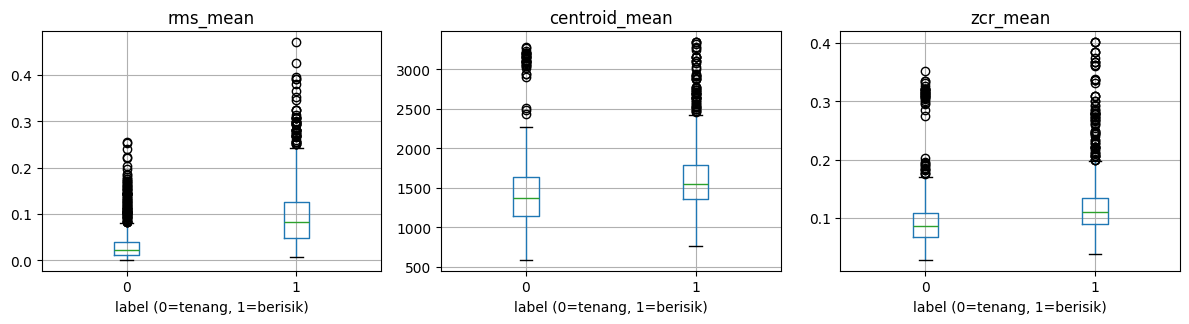

In [8]:
# Eksplorasi singkat: apakah fitur utama memisahkan kedua kelas?
cols = ["rms_mean", "centroid_mean", "zcr_mean"]
print(df.groupby("label")[cols].mean())
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for a, c in zip(ax, cols):
    df.boxplot(column=c, by="label", ax=a)
    a.set_xlabel("label (0=tenang, 1=berisik)")
plt.suptitle(""); plt.tight_layout(); plt.show()

# 11. Perbandingan Model (Group K-Fold)
200 file → ribuan chunk, tetapi chunk dari file yang sama sangat mirip. Karena itu validasi silang memakai
**GroupKFold** (group = file asal) agar tidak bocor. Dibandingkan: model tunggal dan **ensemble (soft voting)**.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, VotingClassifier)
from sklearn.model_selection import GroupKFold, cross_validate, cross_val_predict
from sklearn.base import clone

tr = df[df["split"] == "train"]; te = df[df["split"] == "test"]
X_train, y_train, g_train = tr[ft.FEATURE_NAMES].values, tr["label"].values, tr["file"].values
X_test,  y_test           = te[ft.FEATURE_NAMES].values, te["label"].values

rf  = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
et  = ExtraTreesClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
gb  = GradientBoostingClassifier(random_state=RANDOM_STATE)
svm = make_pipeline(StandardScaler(), SVC(C=3, probability=True, class_weight="balanced", random_state=RANDOM_STATE))
lr  = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced"))
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))

models = {
    "Logistic Regression": lr, "KNN": knn, "SVM (RBF)": svm,
    "Random Forest": rf, "Extra Trees": et, "Gradient Boosting": gb,
    "Ensemble Voting (RF+SVM+GB)": VotingClassifier(
        [("rf", rf), ("svm", svm), ("gb", gb)], voting="soft"),
}

cv = GroupKFold(n_splits=5)
res = {}
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, groups=g_train, cv=cv,
                       scoring=["f1", "precision", "recall"], n_jobs=-1)
    res[name] = {k: s[f"test_{k}"].mean() for k in ["f1", "precision", "recall"]}
    res[name]["f1_std"] = s["test_f1"].std()
results = pd.DataFrame(res).T.sort_values("f1", ascending=False).round(4)
results

,f1,precision,recall,f1_std
KNN,0.8107,0.8101,0.8140,0.0567
SVM (RBF),0.8075,0.8382,0.7848,0.0406
Extra Trees,0.8059,0.8034,0.8132,0.0406
Ensemble Voting (RF+SVM+GB),0.7973,0.8084,0.7920,0.0311
Random Forest,0.7954,0.7948,0.8009,0.0380
Gradient Boosting,0.7909,0.7914,0.7958,0.0370
Logistic Regression,0.7741,0.7963,0.7578,0.0617


In [10]:
# Memilih metode tunggal terbaik: SVM (RBF)
best_name = "SVM (RBF)"
best_model = models[best_name]
print("Model terpilih:", best_name)


Model terpilih: SVM (RBF)


# 12. Tuning Threshold untuk Menekan *False Positive*
Alarm yang berbunyi salah lebih mengganggu daripada alarm yang telat. Threshold dipilih dari prediksi
cross-validation (bukan data uji): ambil threshold terendah yang membuat **precision ≥ target**.

In [11]:
from sklearn.metrics import precision_recall_curve
TARGET_PRECISION = 0.95

proba_cv = cross_val_predict(best_model, X_train, y_train, groups=g_train, cv=cv,
                             method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, proba_cv)
ok = np.where(prec[:-1] >= TARGET_PRECISION)[0]
# tidak pernah di bawah 0.5 agar alarm tetap konservatif
THRESHOLD = max(0.5, float(thr[ok[0]])) if len(ok) else 0.5
if not len(ok): print(f"Peringatan: precision >= {TARGET_PRECISION} tidak tercapai, pakai 0.5")
print(f"Threshold terpilih: {THRESHOLD:.3f}")

Threshold terpilih: 0.938


# 13. Evaluasi pada Data Uji

                   precision    recall  f1-score   support

Tidak Berisik (0)       0.67      0.99      0.80       192
      Berisik (1)       0.98      0.48      0.64       178

         accuracy                           0.74       370
        macro avg       0.82      0.73      0.72       370
     weighted avg       0.82      0.74      0.72       370

F1-Score (kelas Berisik): 0.6415  -> BELUM target >= 0.85


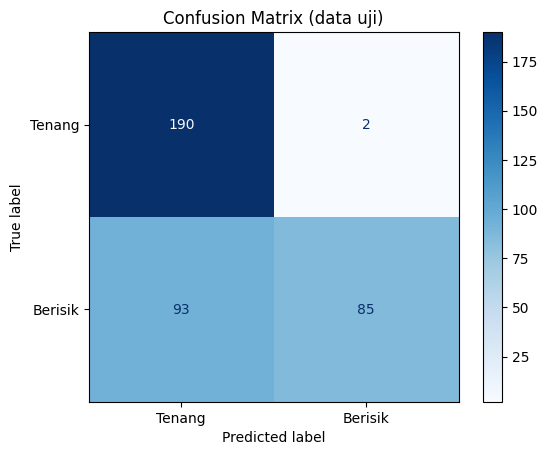

Akurasi level file: 67.50% dari 40 file uji


In [12]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

final_eval = clone(best_model).fit(X_train, y_train)
proba = final_eval.predict_proba(X_test)[:, 1]
pred = (proba >= THRESHOLD).astype(int)

print(classification_report(y_test, pred, target_names=["Tidak Berisik (0)", "Berisik (1)"]))
f1 = f1_score(y_test, pred)
print(f"F1-Score (kelas Berisik): {f1:.4f}  -> {'LOLOS' if f1 >= 0.85 else 'BELUM'} target >= 0.85")
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Tenang", "Berisik"], cmap="Blues")
plt.title("Confusion Matrix (data uji)"); plt.show()

# Evaluasi level file asli (rata-rata prediksi semua chunk dalam satu file)
te_eval = te[["file", "label"]].copy(); te_eval["p"] = proba
per_file = te_eval.groupby("file").agg(label=("label", "first"), p=("p", "mean"))
per_file["pred"] = (per_file["p"] >= THRESHOLD).astype(int)
print(f"Akurasi level file: {(per_file['pred'] == per_file['label']).mean():.2%} dari {len(per_file)} file uji")

# 14. Permutation Feature Importance (SVM RBF)
Karena kernel RBF bekerja pada ruang fitur non-linear (tidak memiliki `feature_importances_` bawaan seperti pohon),
evaluasi pengaruh fitur dilakukan menggunakan **Permutation Feature Importance** pada data uji.


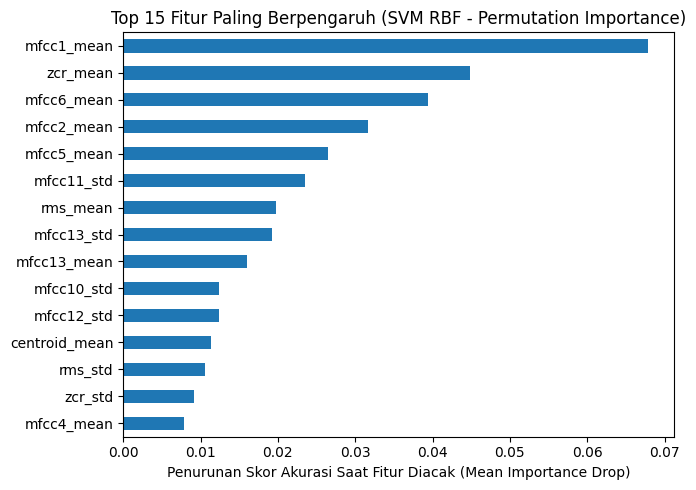

In [13]:
from sklearn.inspection import permutation_importance

# Evaluasi Feature Importance khusus untuk model SVM (RBF)
perm_imp = permutation_importance(final_eval, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm_imp.importances_mean, index=ft.FEATURE_NAMES).sort_values(ascending=False).head(15)
imp[::-1].plot.barh(figsize=(7, 5), title="Top 15 Fitur Paling Berpengaruh (SVM RBF - Permutation Importance)")
plt.xlabel("Penurunan Skor Akurasi Saat Fitur Diacak (Mean Importance Drop)")
plt.tight_layout()
plt.show()


# 15. Uji Kecepatan (Kriteria Operasional < 1 detik)

In [14]:
y_demo = ft.load_audio(test_files["path"].iloc[0])[:ft.CHUNK_LEN]
times = []
for _ in range(10):
    t0 = time.perf_counter()
    x = ft.signal_to_features(y_demo)
    final_eval.predict_proba(x)
    times.append(time.perf_counter() - t0)
print(f"Rata-rata ekstraksi + prediksi: {np.mean(times)*1000:.0f} ms per chunk 5 detik "
      f"-> {'LOLOS' if np.mean(times) < 1 else 'BELUM'} (< 1 detik)")

Rata-rata ekstraksi + prediksi: 28 ms per chunk 5 detik -> LOLOS (< 1 detik)


# 16. Simpan Model untuk Sistem Web
Setelah evaluasi memuaskan, model dilatih ulang pada **seluruh data (train + test)** untuk produksi,
lalu disimpan bersama threshold dan konfigurasinya.

In [15]:
X_all = np.vstack([X_train, X_test]); y_all = np.concatenate([y_train, y_test])
production_model = clone(best_model).fit(X_all, y_all)

joblib.dump({
    "model": production_model,
    "threshold": THRESHOLD,
    "feature_names": ft.FEATURE_NAMES,
    "model_name": best_name,
    "sr": ft.SR,
}, "model_noise.pkl")
print("Tersimpan: model_noise.pkl")

Tersimpan: model_noise.pkl
